# Mixed-mode delamination of IM7/8552: MMB tests of Ratcliffe and Johnston, DCB of Murri and ENF of O'Brien et al.

J. G. Ratcliffe and W. M. Johnston Jr., *Influence of mixed mode I-mode II loading on fatigue delamination growth characteristics of a graphite epoxy tape laminate*, American Society for Composites 29th Technical Conference, La Jolla, CA, 2014, paper 663, NASA NTRS 20140016383, https://ntrs.nasa.gov/citations/20140016383 (no DOI).

G. B. Murri, *Evaluation of delamination onset and growth characterization methods under mode I fatigue loading*, NASA/TM-2013-217966, NASA Langley Research Center, 2013 (no DOI).

T. K. O'Brien, W. M. Johnston and G. J. Toland, *Mode II interlaminar fracture toughness and fatigue characterization of a graphite epoxy composite material*, NASA/TM-2010-216838, NASA Langley Research Center, 2010 (no DOI).

Unidirectional IM7/8552 specimens, $[0]_{24}$, tested at NASA Langley: mixed-mode bending (MMB) at $G_{II}/G$ = 20, 50 and 80% (Ratcliffe and Johnston 2014), double cantilever beam (DCB, Murri 2013) and end-notched flexure (ENF, O'Brien et al. 2010). The three reports give the toughnesses and, for the MMB, one representative load-displacement curve per mode ratio; no finite element analysis of these tests was found. The same material and nearly the same geometry are used by the VCCT benchmark of Krueger, compared with `panels` in [krueger2012_mmb_benchmark](krueger2012_mmb_benchmark.ipynb).

`panels` models the five tests with the coupons of `panels.multidomain.delamination.create_coupon`, two plate arms joined by the mixed-mode bilinear cohesive law (theory: [mixed-mode cohesive zone](../cohesive_zone_mixed_mode.rst)), with CLPT and with FSDT arms. Linear elastic fracture mechanics (LEFM), the corrected beam theory of ASTM D6671/D6671M-22, is computed here as a second reference. The case is the same as case 1 ([mmb_camanho2003_as4peek](mmb_camanho2003_as4peek.ipynb)) with another material and thicker arms.

In [1]:
%matplotlib inline
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath('.'))
import mmb_utils as mu
from panels.multidomain.connections.czm import BilinearLaw

# True runs panels and saves the results in RESULTS, False loads them
RERUN = bool(int(os.environ.get('MMB_RERUN', '0')))
RESULTS = 'results'
REFERENCE = os.path.join('reference_data', 'case1b_im78552')
# comma-separated keys, e.g. MMB50_clpt, runs only these (used to run in parallel)
ONLY = os.environ.get('MMB_TESTS')
ONLY = ONLY.split(',') if ONLY else None

## Specimen and material data

- Ply properties: Ratcliffe and Johnston (2014, p. 7 of the PDF) take $E_{11}$, $E_{22}$ and $G_{13}$ from a report of O'Brien and Krueger (2003) that could not be obtained. The values used here are the IM7/8552 set of the benchmark report of R. Krueger, NASA/CR-2012-217562, Table I, p. 23 of the PDF: $E_{11}$ = 161 GPa, $E_{22} = E_{33}$ = 11.38 GPa, $G_{12} = G_{13}$ = 5.2 GPa, $G_{23}$ = 3.9 GPa, $\nu_{12} = \nu_{13}$ = 0.32, $\nu_{23}$ = 0.45. They are a substitute, not the values of the tests.
- Specimen, Ratcliffe and Johnston (2014), p. 4 and Fig. 1(a), p. 5 of the PDF: 24 unidirectional plies, width 25.4 mm, nominal thickness $2h$ = 4.572 mm (0.18 in), 177.8 mm long. The ply thickness, 0.1905 mm, is inferred (4.572 mm/24 plies); the reports do not print it. Murri (2013, p. 9 of the PDF) gives the average width 25.37 mm and thickness 4.50 mm of the DCB specimens.
- Crack lengths: DCB $a_0$ = 50.8 mm from the load line (Murri 2013, p. 9 of the PDF); ENF $a_0$ = 25.4 mm, the end of the shear precrack 1.0 in from the support (O'Brien et al. 2010, p. 9 of the PDF); MMB at 20% $a_0$ = 25.4 mm, the insert, not precracked (Ratcliffe and Johnston 2014, Fig. 1(a), p. 5, and p. 6 of the PDF). The MMB specimens at 50 and 80% were precracked by about 3 mm (0.12 in, p. 6 of the PDF) at the test mode ratio, and the resulting crack length is not published: $a_0$ = 25.4 + 3 = 28.4 mm is inferred.
- MMB apparatus, Ratcliffe and Johnston (2014): half-span $L$ = 50.8 mm (Fig. 1(a), p. 5 of the PDF); lever lengths $c$ = 92.96, 41.40 and 27.18 mm (3.66, 1.63 and 1.07 in, p. 4 of the PDF). The lever weight and its centre of gravity are not given and are not modelled. The ENF of O'Brien et al. (2010) has the same half-span $L$ = 50.8 mm (Fig. 2(a), p. 9 of the PDF) and is modelled as the MMB apparatus with $c = 0$.
- Toughnesses: $G_{Ic}$ = 0.240 N/mm (Murri 2013, Table 1, p. 14 of the PDF, 239.9 J/m$^2$); $G_{IIc}$ = 0.739 N/mm, the precracked value of O'Brien et al. (2010, p. 19 of the PDF), chosen because the MMB specimens at 50 and 80% were precracked; Benzeggagh-Kenane exponent $\eta$ = 2.1 (Ratcliffe and Johnston 2014, p. 11 of the PDF). The same values are listed in Table I of Ratcliffe and Johnston (2014), p. 11 of the PDF. The measured MMB toughnesses of that table, 0.299 (20%, not precracked), 0.380 (50%) and 0.513 N/mm (80%, precracked), are not used as inputs.
- Strengths: none of the three reports gives one. $\tau_I$ = 60 MPa is chosen, and $\tau_{II} = \tau_I\sqrt{G_{IIc}/G_{Ic}}$ = 105.3 MPa, the shear strength that makes the penalty stiffnesses equal (A. Turon, P. P. Camanho, J. Costa and J. Renart, *Accurate simulation of delamination growth under mixed-mode loading using cohesive elements: definition of interlaminar strengths and elastic stiffness*, Compos. Struct. 2010; 92(8):1857-1864, https://doi.org/10.1016/j.compstruct.2009.12.011, Eq. 23 with $\kappa = k_{sh}/k_I$ = 1).
- Penalty stiffness: $k_I = 10^5$ N/mm$^3$ and the shear stiffness $k_{sh}$ that makes the law consistent, `BilinearLaw(..., KII=None)`, as in case 1 ([mmb_camanho2003_as4peek](mmb_camanho2003_as4peek.ipynb)).

In [2]:
laminaprop = (161000., 11380., 0.32, 5200., 5200., 3900.)   # E11, E22, nu12, G12, G13, G23
plyt, stack = 0.1905, [0]*12                                 # arm: 12 plies, h = 2.286 mm
b, L_dcb = 25.4, 177.8
GIc, GIIc, eta, tauI, KI = 0.240, 0.739, 2.1, 60., 1.e5
tauII = 105.3                                        # tauI*sqrt(GIIc/GIc), to 0.1 MPa
law = BilinearLaw(GIc, GIIc, tauI, tauII, KI, eta)
print(law)

# B = G_II/G (nominal), a0, L, c; delta_max: last load-point displacement of the runs
tests = {
    'DCB':   dict(kind='DCB', B=0.0, a0=50.8, x_end=L_dcb, delta_max=5.0905),
    'MMB20': dict(kind='MMB', B=0.2, a0=25.4, L=50.8, c=92.96, delta_max=3.335),
    'MMB50': dict(kind='MMB', B=0.5, a0=28.4, L=50.8, c=41.40, delta_max=2.6513),
    'MMB80': dict(kind='MMB', B=0.8, a0=28.4, L=50.8, c=27.18, delta_max=2.984),
    'ENF':   dict(kind='ENF', B=1.0, a0=25.4, L=50.8, delta_max=2.4473),
}

BilinearLaw(GIc=0.24, GIIc=0.739, tauI=60.0, tauII=105.3, KI=100000.0, eta=2.1, KII=100027.87550744248)


## Reference data

**Load-displacement curves of the MMB tests**, Ratcliffe and Johnston (2014), Fig. 5(a), p. 11 of the PDF: one representative specimen per mode ratio ("only a single example of each is shown"). The figure is a vector drawing; each curve was read from the polyline of the PDF and calibrated on the axis ticks, $\pm$0.009 mm and $\pm$0.94 N, with vertices about one sample apart. The same curves are in Fig. 1(a) of the raw-data report of Ratcliffe and Johnston (2021, NASA NTRS 20210018779), whose data files are not online. The unloading branches are not shown.

**Peak loads.** The reports tabulate toughnesses, not loads; the peaks of the tests are the maxima of the digitised curves, 115.3, 341.5 and 531.8 N at 2.40, 1.90 and 2.01 mm. Murri (2013, Fig. 4, p. 10 of the PDF) and O'Brien et al. (2010, Fig. 6, p. 12 of the PDF) plot one typical DCB and ENF curve; these are not digitised and the DCB and ENF are compared with LEFM only.

In [3]:
# peak loads (N): (source, kind, value)
ref_peaks = {
    'DCB': [], 'ENF': [],
    'MMB20': [('Test, Ratcliffe 2014 Fig. 5(a), digitised', 'test', 115.3)],
    'MMB50': [('Test, Ratcliffe 2014 Fig. 5(a), digitised', 'test', 341.5)],
    'MMB80': [('Test, Ratcliffe 2014 Fig. 5(a), digitised', 'test', 531.8)],
}
curves = {key: {'Test (Ratcliffe 2014, Fig. 5a)': mu.read_curve(
                    os.path.join(REFERENCE, 'Ratcliffe2014_Fig5a_GIIGT{0}.csv'.format(B)),
                    loading_only=True) + ('test',)}
          for key, B in (('MMB20', '0.2'), ('MMB50', '0.5'), ('MMB80', '0.8'))}
for key in ('DCB', 'ENF'):
    curves[key] = {}

## Linear elastic fracture mechanics

Corrected beam theory of ASTM D6671/D6671M-22 (`mmb_utils.lefm_curve`), as in [mmb_camanho2003_as4peek](mmb_camanho2003_as4peek.ipynb): self-similar growth at the Benzeggagh-Kenane toughness at the nominal mode ratio up to $a = L$. For the DCB, the width and thickness measured by Murri (2013), 25.37 and 2 $\times$ 2.25 mm, are used, as in the study of the mixed-mode model; the `panels` model and the other tests use the nominal 25.4 and 2 $\times$ 2.286 mm. The LEFM peak of the DCB with the nominal dimensions is printed too.

In [4]:
E11, E22, _, _, G13, _ = laminaprop
h = plyt*len(stack)
print('chi = {0:.3f}, chi h = {1:.3f} mm'.format(mu.chi(E11, E22, G13), mu.chi(E11, E22, G13)*h))
lefm = {}
for key, t in tests.items():
    Gc = mu.bk(GIc, GIIc, eta, t['B'])
    bt, ht = (25.37, 2.25) if key == 'DCB' else (b, h)
    lefm[key] = mu.lefm_curve(t['kind'], E11, E22, G13, bt, ht, t['a0'], Gc, L=t.get('L'), c=t.get('c', 0.))
    if t['kind'] == 'MMB':
        print('{0}: lever length of D6671 Eq. 5 for B = {1}: {2:.1f} mm (used: {3} mm)'.format(
              key, t['B'], mu.lever_length(t['B'], t['a0'], h, mu.chi(E11, E22, G13), t['L']), t['c']))
d, P, a = mu.lefm_curve('DCB', E11, E22, G13, b, h, tests['DCB']['a0'], GIc)
print('DCB, LEFM peak with b = {0} and h = {1:.3f} mm: {2:.1f} N'.format(b, h, P.max()))

chi = 1.954, chi h = 4.466 mm
MMB20: lever length of D6671 Eq. 5 for B = 0.2: 92.5 mm (used: 92.96 mm)
MMB50: lever length of D6671 Eq. 5 for B = 0.5: 41.5 mm (used: 41.4 mm)
MMB80: lever length of D6671 Eq. 5 for B = 0.8: 27.3 mm (used: 27.18 mm)
DCB, LEFM peak with b = 25.4 and h = 2.286 mm: 90.1 N


## panels model

Coupons of `create_coupon` (see its docstring for the supports, the lever and the load), as in [mmb_camanho2003_as4peek](mmb_camanho2003_as4peek.ipynb): each arm is a cracked domain, seven cohesive domains from the crack tip and a far domain with the same cohesive law; contact over the pre-crack; domains joined with the null-space method; the lever constraint of the MMB on the mean deflections across the width. The DCB has the slope of the upper arm zero at the far end, 177.8 mm from the load line.

Discretisation, the rules of the study of the mixed-mode model (`mmb_utils.discretisation`), with $n = 4$ terms and 6 Gauss points across the width and 10 terms along $x$ in the cracked and far domains:

- CLPT arms: seven cohesive domains over 67.5 mm (9.64 mm each), $m$ = 18 terms, $1.25\,r L_{dom}$ with $r = \max(\lambda_I, \mu)$ the larger decay rate of the opening and of the sliding, and 240 Gauss points along $x$ per domain, about 17 per cohesive zone length $l_{cz} = 0.88 E_{22} G_{Ic}/\tau_I^2$ = 0.67 mm;
- FSDT arms: seven cohesive domains over 30 mm (4.29 mm each), $m$ = 25 terms and 108 Gauss points (25 per mm), the rule extended with the fast decay rate of the opening of shear-deformable arms, 4.5 mm$^{-1}$; for the MMB at 80% the CLPT domains (67.5 mm, $m$ = 18, 240 points), which reach the end of the propagation. The extended rule changed the FSDT peaks of the DCB and of the MMB at 20 and 50% by less than 0.4% from those of the CLPT domains (study of the mixed-mode model).

Solver (`solve_coupon`): Newton-Raphson, displacement increments of 0.1 mm (the largest; cut automatically down to $10^{-5}$ mm), relative tolerance $10^{-9}$; for the MMB at 80% and the ENF (both theories), control of the separation at the load line (`control='load-line'`) up to a crack length of 50 mm, which follows the snap-back after the peak. The last displacement is twice the displacement at the LEFM peak. The peak loads are taken before the crack reaches the saddle, $a < L$. These are the settings of the runs reported in the study of the mixed-mode model; the runs were made four at a time, one thread each, on a laptop shared with other runs, and the table at the end gives their run times and the computer. The stored result of the ENF with FSDT arms is the run of the study's driver with the same commit, inputs and settings (`ENF_a25.4_fsdt_fsdtrule_loadline_cb23e30_20261123_225507`), converted with `mmb_utils.convert_study_run`, which checks them.

In [5]:
def disc_of(key, model):
    """Cohesive domains and the theory of the rule that sizes them"""
    if model == 'clpt' or key == 'MMB80':
        return dict(L_coh=67.5, nd=7, nr_x_gauss=240, rule='clpt')
    return dict(L_coh=30., nd=7, nr_x_gauss=108, rule='fsdt')


for model in ('clpt', 'fsdt'):
    for key in ('DCB', 'MMB80'):
        dk = disc_of(key, model)
        disc = mu.discretisation(laminaprop, h, [law], dk['L_coh'], dk['nd'], model=dk['rule'],
                                 nr_x_gauss=dk['nr_x_gauss'])
        print(model, key, {k: round(v, 3) if isinstance(v, float) else v for k, v in disc.items()})


def inputs_of(key, model):
    t = tests[key]
    dk = disc_of(key, model)
    disc = mu.discretisation(laminaprop, h, [law], dk['L_coh'], dk['nd'], model=dk['rule'],
                             nr_x_gauss=dk['nr_x_gauss'])
    inp = dict(kind=t['kind'], laminaprop=laminaprop, plyt=plyt, stack=stack, b=b, a0=t['a0'],
               laws=[mu.law_dict(law)], model=model, nd=disc['nd'], L_coh=dk['L_coh'], m_crack=10,
               m_coh=disc['m_coh'], m_far=10, n=4, nr_x_gauss=disc['nr_x_gauss'], nr_y_gauss=6)
    if t['kind'] == 'DCB':
        inp['x_end'] = t['x_end']
    else:
        inp['L'] = t['L']
        if t['kind'] == 'MMB':
            inp['c'] = t['c']
    return inp


def solver_of(key, model):
    s = dict(delta_max=tests[key]['delta_max'], inc=0.1, min_inc=1e-5, relTOL=1e-9)
    if key in ('MMB80', 'ENF'):
        s.update(control='load-line', a_stop=50.)
    return s


runs = {}
for key in tests:
    for model in ('fsdt', 'clpt'):
        name = '{0}_{1}'.format(key, model)
        if ONLY is not None and name not in ONLY:
            continue
        path = os.path.join(RESULTS, 'mmb_ratcliffe2014_im78552_{0}.npz'.format(name))
        runs[name] = mu.run_or_load(inputs_of(key, model), solver_of(key, model), path, rerun=RERUN)

clpt DCB {'lambda_I': 0.747, 'mu': 1.475, 'r_fast_fsdt': 0.0, 'l_cz': 0.668, 'L_dom': 9.643, 'nd': 7, 'm_coh': 18, 'nr_x_gauss': 240}
clpt MMB80 {'lambda_I': 0.747, 'mu': 1.475, 'r_fast_fsdt': 0.0, 'l_cz': 0.668, 'L_dom': 9.643, 'nd': 7, 'm_coh': 18, 'nr_x_gauss': 240}
fsdt DCB {'lambda_I': 0.747, 'mu': 1.475, 'r_fast_fsdt': 4.492, 'l_cz': 0.668, 'L_dom': 4.286, 'nd': 7, 'm_coh': 25, 'nr_x_gauss': 108}
fsdt MMB80 {'lambda_I': 0.747, 'mu': 1.475, 'r_fast_fsdt': 0.0, 'l_cz': 0.668, 'L_dom': 9.643, 'nd': 7, 'm_coh': 18, 'nr_x_gauss': 240}


## Results

Peak loads: tests, LEFM and `panels`; the differences are to LEFM.

In [6]:
rows = []
for key, t in tests.items():
    for s, k, p in ref_peaks[key]:
        rows.append((key, s, p))
    rows.append((key, 'LEFM (ASTM D6671)', float(lefm[key][1].max())))
    for model in ('fsdt', 'clpt'):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            rows.append((key, 'panels ' + model.upper(), mu.peak_load(res, t.get('L'))[0]))
display(Markdown(mu.peaks_table(rows, ref='LEFM (ASTM D6671)')))

| test | source | $P_{max}$ (N) | vs LEFM (ASTM D6671) |
|---|---|---|---|
| DCB | LEFM (ASTM D6671) | 88.0 | - |
| DCB | panels FSDT | 88.8 | +0.9% |
| DCB | panels CLPT | 92.7 | +5.3% |
| MMB20 | Test, Ratcliffe 2014 Fig. 5(a), digitised | 115.3 | -16.2% |
| MMB20 | LEFM (ASTM D6671) | 137.6 | - |
| MMB20 | panels FSDT | 135.7 | -1.4% |
| MMB20 | panels CLPT | 145.3 | +5.6% |
| MMB50 | Test, Ratcliffe 2014 Fig. 5(a), digitised | 341.5 | -5.5% |
| MMB50 | LEFM (ASTM D6671) | 361.2 | - |
| MMB50 | panels FSDT | 352.5 | -2.4% |
| MMB50 | panels CLPT | 369.8 | +2.4% |
| MMB80 | Test, Ratcliffe 2014 Fig. 5(a), digitised | 531.8 | -21.0% |
| MMB80 | LEFM (ASTM D6671) | 673.3 | - |
| MMB80 | panels FSDT | 657.9 | -2.3% |
| MMB80 | panels CLPT | 681.4 | +1.2% |
| ENF | LEFM (ASTM D6671) | 1480.3 | - |
| ENF | panels FSDT | 1449.5 | -2.1% |
| ENF | panels CLPT | 1450.3 | -2.0% |

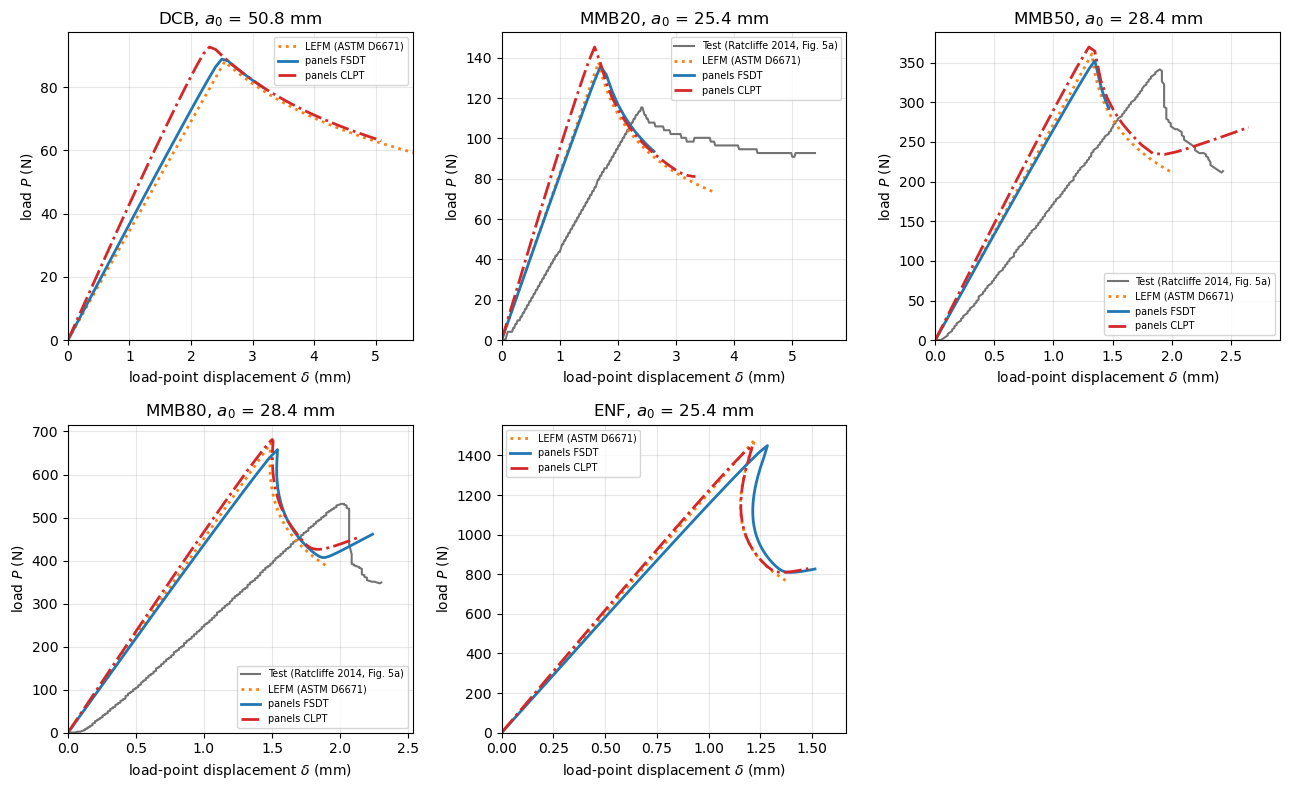

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (key, t) in zip(axes.flat, tests.items()):
    cs = {}
    for label, (d, p, kind) in curves[key].items():
        cs[label] = (d, p, dict(color='0.45', lw=1.5))
    cs['LEFM (ASTM D6671)'] = (lefm[key][0], lefm[key][1], dict(color='C1', ls=':', lw=2))
    for model, col in (('fsdt', 'C0'), ('clpt', 'C3')):
        res = runs.get('{0}_{1}'.format(key, model))
        if res is not None:
            cs['panels ' + model.upper()] = (np.r_[0., res['delta']], np.r_[0., res['P']],
                                             dict(color=col, lw=2, ls='-' if model == 'fsdt' else '-.'))
    mu.plot_test(ax, cs, title='{0}, $a_0$ = {1} mm'.format(key, t['a0']))
    xs = [np.nanmax(c[0]) for k, c in cs.items() if not k.startswith('LEFM')]
    ax.set_xlim(0, 1.1*max(xs) if xs else None)
    ax.legend(fontsize=7)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [8]:
info = ['| run | status | increments | last crack length (mm) | size | run time (min) | panels | machine |',
        '|---|---|---|---|---|---|---|---|']
for name, res in runs.items():
    info.append('| {0} | {1} | {2} | {3:.1f} | {4} | {5:.1f} | {6} ({7}) | {8} |'.format(
        name, res['status'], len(res['delta']), res['a'][-1], res['size'], res['time']/60,
        res['panels_version'], res['panels_commit'][:7], res['machine']))
display(Markdown('\n'.join(info)))

| run | status | increments | last crack length (mm) | size | run time (min) | panels | machine |
|---|---|---|---|---|---|---|---|
| DCB_fsdt | stopped at delta = 3.1733 | 58 | 57.2 | 7800 | 30.2 | 0.16.0 (439b8fb) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| DCB_clpt | finished | 51 | 75.9 | 3504 | 4.9 | 0.16.0 (439b8fb) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB20_fsdt | stopped at delta = 2.6212 | 92 | 39.3 | 7800 | 34.6 | 0.16.0 (cb23e30) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB20_clpt | finished | 34 | 48.2 | 3504 | 4.2 | 0.16.0 (439b8fb) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB50_fsdt | stopped at delta = 1.4695 | 101 | 35.0 | 7800 | 59.5 | 0.16.0 (439b8fb) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB50_clpt | finished | 30 | 53.0 | 3504 | 4.2 | 0.16.0 (439b8fb) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB80_fsdt | finished | 150 | 50.1 | 5840 | 34.0 | 0.16.0 (439b8fb) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| MMB80_clpt | finished | 114 | 50.1 | 3504 | 12.1 | 0.16.0 (439b8fb) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| ENF_fsdt | stopped at delta = 1.5131638724360688 | 76 | 50.2 | 7800 | 23.9 | 0.16.0 (560129f) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |
| ENF_clpt | finished | 67 | 50.2 | 3504 | 4.2 | 0.16.0 (cb23e30) | AMD Ryzen 7 PRO 250 w/ Radeon 780M Graphics, 16 logical processors, Windows 11 |

## Discussion

- **panels and LEFM.** With the same inputs, the FSDT peak loads are within 2.4% of the corrected beam theory: +0.9% (DCB), $-1.4$, $-2.4$ and $-2.3$% (MMB 20, 50 and 80%) and $-2.1$% (ENF; CLPT $-2.0$%). The LEFM peak of the DCB uses the dimensions measured by Murri (2013); with the nominal dimensions of the model it is 90.1 N, 1.4% above the FSDT peak.
- **CLPT and FSDT arms.** The CLPT arms give peak loads 4.3% (DCB), 7.0% (MMB 20%), 4.9% (MMB 50%) and 3.6% (MMB 80%) above the FSDT arms, and the same peak for the ENF (1450.3 against 1449.5 N), more than for the thinner AS4/PEEK arms of [mmb_camanho2003_as4peek](mmb_camanho2003_as4peek.ipynb) (3.1, 1.8, 1.0 and 0.7%): the arms are thicker here ($h$ = 2.29 against 1.56 mm, with $E_{11}/G_{13}$ = 31) and the transverse shear that CLPT neglects matters more.
- **Tests.** The peak loads of the three MMB tests lie 16% (20%), 5.5% (50%) and 21% (80%) below LEFM and both `panels` models, and their secant stiffness at the peak, 48, 180 and 264 N/mm, is 34-42% below the initial stiffness of LEFM (82.5, 272.5 and 451.3 N/mm): the tests are much more compliant than any of the models. A cause on the side of the tests is likely but could not be resolved: the elastic constants are a substitute, the crack lengths of the precracked specimens (50 and 80%) are not published, the lever weight is unknown, and the displacement may include the compliance of the machine. The toughnesses come from other test series (Murri 2013; O'Brien et al. 2010). No input was adjusted to reduce these differences.
- **Robustness.** With FSDT arms under control of the load-point displacement, the DCB and the MMB at 20 and 50% slow down after the peak to increments of $10^{-5}$ mm, the load falling at a nearly constant displacement as rows of integration points fail one after the other, and stop when the increment would fall below the minimum (status in the table above); the peaks are reached. The MMB at 80% passes the snap-back with the control of the separation at the load line. The ENF has $a_0/L$ = 0.5 and snaps back at the onset of propagation. The control of the separation at the load line follows the snap-back to $a$ = 50 mm, with a peak of 1450.3 N at $\delta$ = 1.21 mm with CLPT arms and 1449.5 N at $\delta$ = 1.28 mm with FSDT arms. Under control of the load-point displacement, the FSDT run had stopped at the onset, with the crack length still $a_0$, at 1449.7 N. The study of the mixed-mode model reported 1435.3 N for the CLPT ENF, from a run with an earlier version of `panels` (commit 3a68707) whose increments of the controlled separation stepped over the peak, from 1435.3 N at $a = a_0$ directly to $a$ = 30.6 mm; the run here, with the tangent of the pristine interface corrected in commit cb23e30, resolves the peak with smaller increments. Between these commits the load-line control of the ENF took no step at all, the controlled opening being zero in the linear solution.